# 05 · Transfer learning: a pretrained ResNet18 (deliverable 3)

A dense network flattens the painting and loses its 2-D structure (S05, S07). A **convolutional** network looks at small neighbourhoods with the same filters everywhere, and builds edges → textures → object parts → objects, layer after layer (S07).
With only ~2 300 training images we do not train a CNN from scratch: we start from a **ResNet18 pretrained on ImageNet** (1.2 million photos) and adapt it to our genres, as in TP07 Part D:

1. replace its last layer by a new one for our classes, **freeze** the rest and train the **head** only;
2. paintings are very different from ImageNet photos (S07, transfer-learning table): **unfreeze the last block** (`layer4`) and **fine-tune** it with a smaller learning rate;
3. compare both on validation, measure the chosen one **once** on the test set, with its CPU cost for the kiosk.

## 0. Setup

In [1]:
import copy, json, math, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sys.path.insert(0, "../src")                 # the team's shared code
from museum_guide.data import prepare_subset

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

ROOT = Path("..")
IMG_SIZE = 128            # our images are 128x128 (TP07 uses 64 on a CPU; 224 = ImageNet, more accurate but slower)
FIG_DIR = ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "data" / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)    # weights stay out of Git
print("device:", device)

device: cpu


## 1. Prepare the images like the pre-training
*"A pretrained model must always receive inputs prepared like during its pre-training"* (TP07): resize, then normalise each channel with the **ImageNet** mean (0.485, 0.456, 0.406) and std (0.229, 0.224, 0.225) (S07).
`prepare_subset` gives the team's split (same images as every other model) but standardised with *our* statistics: we undo that first, back to pixels in [0, 1].

In [2]:
data = prepare_subset("genre", seed=SEED)
class_names = data["classes"]
C = len(class_names)
idx = {"train": data["train_idx"], "val": data["val_idx"], "test": data["test_idx"]}

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def prepare(X):
    X = X * data["std"] + data["mean"]                                           # undo the team standardisation: [0, 1]
    X = F.interpolate(X, size=IMG_SIZE, mode="bilinear", align_corners=False)    # resize
    return (X - IMAGENET_MEAN) / IMAGENET_STD                                    # ImageNet normalisation


X_img = prepare(data["X"])
y_all = data["y"]
data["X"] = None                                                                 # free the memory

full_set = TensorDataset(X_img, y_all)
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(Subset(full_set, idx["train"]), batch_size=64, shuffle=True, generator=g)
val_loader = DataLoader(Subset(full_set, idx["val"]), batch_size=128)
test_loader = DataLoader(Subset(full_set, idx["test"]), batch_size=128)

print(C, "classes:", class_names)
print("images:", tuple(X_img.shape), "|", {s: len(i) for s, i in idx.items()})
print("train mean per channel:", X_img[torch.as_tensor(idx["train"])].mean(dim=(0, 2, 3)).round(decimals=2).tolist())

11 classes: ['Unknown Genre', 'abstract_painting', 'cityscape', 'genre_painting', 'illustration', 'landscape', 'nude_painting', 'portrait', 'religious_painting', 'sketch_and_study', 'still_life']
images: (3300, 3, 128, 128) | {'train': 2309, 'val': 496, 'test': 495}
train mean per channel: [0.28999999165534973, 0.20000000298023224, 0.10999999940395355]


## 2. Load ResNet18, replace the head, freeze the backbone (S07)
`model.fc` is an `nn.Linear(512, 1000)` for the 1 000 ImageNet classes: we replace it by a new `nn.Linear(512, C)` (random weights).
`requires_grad = False`: autograd computes no gradient for these weights and the optimiser does not move them (S07).

In [3]:
def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


torch.manual_seed(SEED)
model = resnet18(weights=ResNet18_Weights.DEFAULT)       # weights learned on ImageNet (45 MB, downloaded once)
print("original head:", model.fc)
model.fc = nn.Linear(512, C)                              # new head for our genres
for p in model.parameters():
    p.requires_grad = False                               # freeze everything...
for p in model.fc.parameters():
    p.requires_grad = True                                # ...except the new head
model = model.to(device)

n_trainable = count_parameters(model, trainable_only=True)
print("new head:", model.fc)
print(f"trainable: {n_trainable:,} of {count_parameters(model):,} parameters  (512 x {C} + {C} = {512 * C + C})")

original head: Linear(in_features=512, out_features=1000, bias=True)
new head: Linear(in_features=512, out_features=11, bias=True)
trainable: 5,643 of 11,182,155 parameters  (512 x 11 + 11 = 5643)


## 3. Train the head (S04 loop, S06 early stopping)
- `fit_transfer` follows TP07: the model stays in `eval()` mode while training, so that the batch-norm layers keep the statistics learned on ImageNet (the trainable weights are still updated normally).
- Early stopping as in TP06 Exercise 10: keep a copy of the weights of the best validation epoch, stop after `patience` epochs without improvement, reload the best weights.
- Sanity check (S08): before training, the loss should be close to $\ln C$.

In [4]:
loss_fn = nn.CrossEntropyLoss()


def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def fit_transfer(model, optimizer, max_epochs, patience):
    torch.manual_seed(1)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.eval()                                  # batch norm keeps its ImageNet statistics (TP07)
        total, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()                     # the 5 lines of the training loop (S04)
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(total / n); history["train_acc"].append(correct / n)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        print(f"epoch {epoch:2d} | train loss {total / n:.3f} acc {correct / n:.3f} | "
              f"val loss {val_loss:.3f} acc {val_acc:.3f} | {time.time() - t0:.0f} s")
        if val_loss < best_loss:                      # early stopping (TP06 Exercise 10)
            best_loss, best_state, best_epoch, wait = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                print(f"early stopping: no improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)                 # back to the best epoch
    history["best_epoch"], history["time_s"] = best_epoch, time.time() - t0
    return history


def plot_history(history, title, filename):
    e = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(e, history["train_loss"], label="train"); axes[0].plot(e, history["val_loss"], label="validation")
    axes[1].plot(e, history["train_acc"], label="train"); axes[1].plot(e, history["val_acc"], label="validation")
    for ax, name in zip(axes, ["loss", "accuracy"]):
        ax.axvline(history["best_epoch"], ls="--", c="grey", lw=1); ax.set_xlabel("epoch"); ax.set_ylabel(name)
        ax.legend(); ax.grid(alpha=.3)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG_DIR / filename, dpi=150); plt.show()


init_loss, init_acc = evaluate(model, val_loader, loss_fn)
print(f"before training: val loss {init_loss:.3f} (ln C = {math.log(C):.3f}), val acc {init_acc:.3f} (chance {1 / C:.3f})")

before training: val loss 2.855 (ln C = 2.398), val acc 0.083 (chance 0.091)


epoch  1 | train loss 2.142 acc 0.269 | val loss 1.642 acc 0.470 | 54 s
epoch  2 | train loss 1.459 acc 0.517 | val loss 1.450 acc 0.534 | 104 s
epoch  3 | train loss 1.275 acc 0.579 | val loss 1.389 acc 0.562 | 158 s
epoch  4 | train loss 1.195 acc 0.608 | val loss 1.370 acc 0.565 | 212 s
epoch  5 | train loss 1.101 acc 0.633 | val loss 1.366 acc 0.550 | 265 s
epoch  6 | train loss 1.056 acc 0.654 | val loss 1.370 acc 0.562 | 318 s
epoch  7 | train loss 1.006 acc 0.666 | val loss 1.373 acc 0.552 | 372 s
epoch  8 | train loss 0.966 acc 0.682 | val loss 1.361 acc 0.560 | 424 s
epoch  9 | train loss 0.952 acc 0.691 | val loss 1.369 acc 0.569 | 477 s
epoch 10 | train loss 0.911 acc 0.704 | val loss 1.364 acc 0.560 | 515 s
epoch 11 | train loss 0.887 acc 0.708 | val loss 1.405 acc 0.560 | 549 s
early stopping: no improvement for 3 epochs


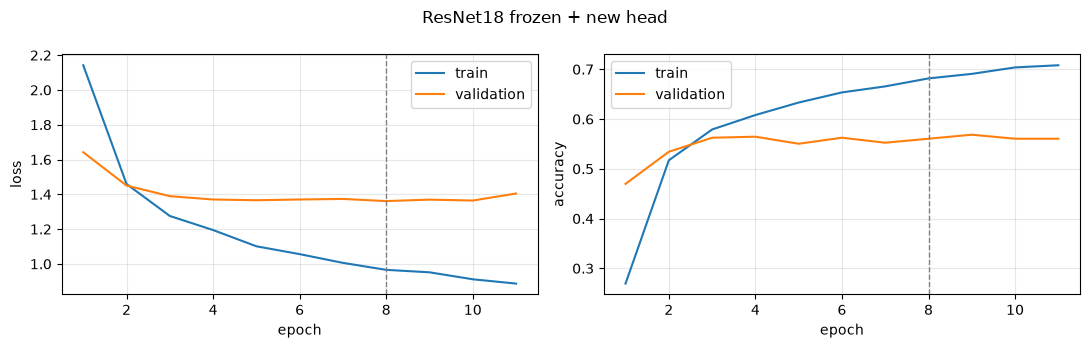

head only: best validation accuracy 0.560 at epoch 8 (549 s)


In [5]:
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)      # the head only (S07)
history_head = fit_transfer(model, optimizer, max_epochs=15, patience=3)
acc_head = history_head["val_acc"][history_head["best_epoch"] - 1]
torch.save(model.state_dict(), MODEL_DIR / "resnet18_head.pt")
plot_history(history_head, "ResNet18 frozen + new head", "resnet_head_curves.png")
print(f"head only: best validation accuracy {acc_head:.3f} at epoch {history_head['best_epoch']} "
      f"({history_head['time_s']:.0f} s)")

**Reading:** with the backbone frozen, only the new head (5 643 parameters) is trained. Learning is fast: the validation accuracy reaches 57 % at epoch 3, then plateaus around 56-57 % while the training accuracy keeps rising (from 57 % to 71 %): the gap between train and validation opens, the start of over-fitting. At epoch 11 the validation loss goes back up (1.41), so early stopping stops the run and reloads the weights of epoch 8, the best validation loss (1.364). **Best validation accuracy: 57.1 %**, more than twice the logistic regression on pixels (26.8 %) and 6 times chance (9.1 %), in 61 s of training. Same kind of classifier as the baseline (one neuron per genre), but on the 512 ResNet features instead of raw pixels: the pretrained convolutions see shapes and objects. The plateau shows the limit of frozen features learned on photos: fine-tuning the last block should adapt them to paintings (next issue).

## 4. Fine-tune the last block (S07, TP07 Exercise 16)
`layer4` computes the most specific features, the ones most tied to ImageNet photos. Paintings are "very different" data (S07): we unfreeze `layer4` and train it with the head, with **two learning rates** (parameter groups): small for the pretrained weights (we only adjust them, we do not want to destroy them), larger for the head.

In [6]:
for p in model.layer4.parameters():
    p.requires_grad = True
optimizer = torch.optim.Adam([{"params": model.layer4.parameters(), "lr": 1e-4},
                              {"params": model.fc.parameters(), "lr": 1e-3}])
print(f"trainable: {count_parameters(model, trainable_only=True):,} of {count_parameters(model):,} parameters "
      f"(layer4: {count_parameters(model.layer4):,})")

trainable: 8,399,371 of 11,182,155 parameters (layer4: 8,393,728)


epoch  1 | train loss 1.170 acc 0.612 | val loss 1.335 acc 0.587 | 41 s
epoch  2 | train loss 0.572 acc 0.815 | val loss 1.421 acc 0.548 | 93 s
epoch  3 | train loss 0.237 acc 0.931 | val loss 1.675 acc 0.585 | 169 s
epoch  4 | train loss 0.070 acc 0.988 | val loss 1.906 acc 0.556 | 240 s
early stopping: no improvement for 3 epochs


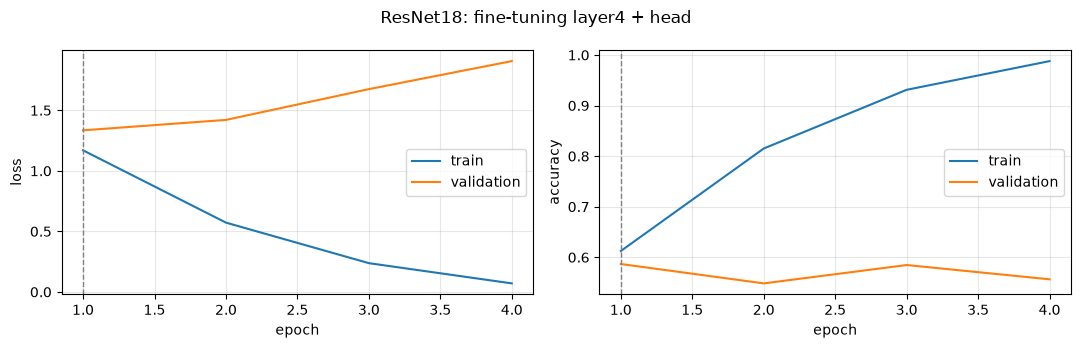

fine-tuned: best validation accuracy 0.587 at epoch 1 (240 s)


In [7]:
history_ft = fit_transfer(model, optimizer, max_epochs=10, patience=3)
acc_ft = history_ft["val_acc"][history_ft["best_epoch"] - 1]
torch.save(model.state_dict(), MODEL_DIR / "resnet18_finetuned.pt")
plot_history(history_ft, "ResNet18: fine-tuning layer4 + head", "resnet_finetune_curves.png")
print(f"fine-tuned: best validation accuracy {acc_ft:.3f} at epoch {history_ft['best_epoch']} "
      f"({history_ft['time_s']:.0f} s)")

**Reading:** unfreezing `layer4` raises the number of trainable parameters from 5 643 to 8.4 million for only 2 309 training images, and the network over-fits very fast: the training accuracy jumps from 61 % to 98.6 % in 4 epochs (training loss 1.17 → 0.08), while the validation loss rises from the first epoch (1.33 → 1.93) and the validation accuracy stays around 55-58 %. Early stopping (S06) stops at epoch 4 and reloads epoch 1, the best validation loss. **Best validation accuracy: 58.5 %**, vs 57.1 % for the head alone: +1.4 points (≈ 7 images out of 496), a small gain close to the noise. Diagnosis (S06 table): *"train loss goes down, validation goes up" → over-fitting*. With so few images, adapting 8.4 M pretrained weights is risky; the step of 1e-4 is probably too large for them.

### Fix attempt: a 10× smaller learning rate for layer4 (one change at a time, S08)
The pretrained weights "only need small adjustments" (S07): we restart from the head-only model and fine-tune `layer4` with lr = 1e-5 instead of 1e-4, everything else unchanged.

epoch  1 | train loss 0.968 acc 0.668 | val loss 1.433 acc 0.542 | 59 s
epoch  2 | train loss 0.773 acc 0.739 | val loss 1.425 acc 0.552 | 122 s
epoch  3 | train loss 0.635 acc 0.798 | val loss 1.482 acc 0.548 | 185 s
epoch  4 | train loss 0.527 acc 0.845 | val loss 1.494 acc 0.558 | 223 s
epoch  5 | train loss 0.412 acc 0.890 | val loss 1.558 acc 0.550 | 262 s
early stopping: no improvement for 3 epochs


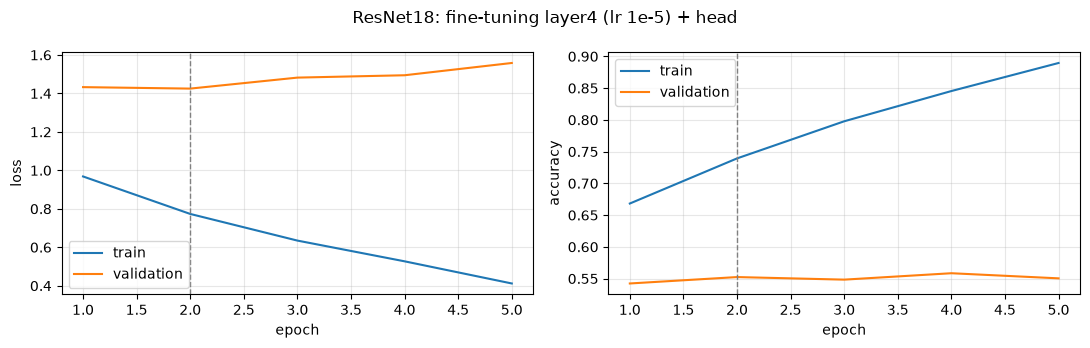

fine-tuned (layer4 lr 1e-5): best validation accuracy 0.552 at epoch 2 (262 s)


In [8]:
model.load_state_dict(torch.load(MODEL_DIR / "resnet18_head.pt", map_location=device))   # back to the head-only model
optimizer = torch.optim.Adam([{"params": model.layer4.parameters(), "lr": 1e-5},
                              {"params": model.fc.parameters(), "lr": 1e-3}])
history_ft2 = fit_transfer(model, optimizer, max_epochs=10, patience=3)
acc_ft2 = history_ft2["val_acc"][history_ft2["best_epoch"] - 1]
torch.save(model.state_dict(), MODEL_DIR / "resnet18_finetuned_lr1e-5.pt")
plot_history(history_ft2, "ResNet18: fine-tuning layer4 (lr 1e-5) + head", "resnet_finetune_lr1e-5_curves.png")
print(f"fine-tuned (layer4 lr 1e-5): best validation accuracy {acc_ft2:.3f} at epoch {history_ft2['best_epoch']} "
      f"({history_ft2['time_s']:.0f} s)")

**Reading:** with a 10× smaller learning rate for `layer4` (1e-5, the only change), the network memorises more slowly (training accuracy 67 % → 89 % in 5 epochs, instead of 61 % → 99 % in 4), but the validation does not improve: its loss rises from epoch 3 and the best validation accuracy is 56.5 % (epoch 2, loss 1.423). The three ResNet variants are within 2 points of each other (head only 57.1 %, fine-tuned lr 1e-4 58.5 %, lr 1e-5 56.5 %): with 496 validation images (uncertainty ≈ ±2 points) these differences are within the noise (S08). **Conclusion: with 2 309 training images, fine-tuning `layer4` brings no clear gain over the frozen backbone; the pretrained features already do most of the work, and adapting 8.4 M weights mostly leads to over-fitting.**

## 5. Head alone vs fine-tuned (on validation)
The model is chosen on **validation** (S04); the test set is used only once, in the next section.

head only                    validation accuracy 0.560
fine-tuned, layer4 lr 1e-4   validation accuracy 0.587
fine-tuned, layer4 lr 1e-5   validation accuracy 0.552

model chosen on validation: fine-tuned, layer4 lr 1e-4 | check: 0.587


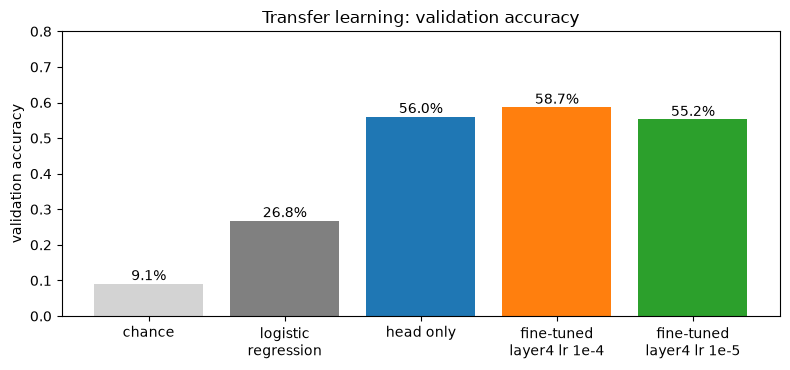

In [9]:
candidates = {
    "resnet18_head": ("head only", acc_head, "resnet18_head.pt"),
    "resnet18_finetuned_lr1e-4": ("fine-tuned, layer4 lr 1e-4", acc_ft, "resnet18_finetuned.pt"),
    "resnet18_finetuned_lr1e-5": ("fine-tuned, layer4 lr 1e-5", acc_ft2, "resnet18_finetuned_lr1e-5.pt"),
}
for key, (label, acc, _) in candidates.items():
    print(f"{label:28s} validation accuracy {acc:.3f}")

chosen = max(candidates, key=lambda k: candidates[k][1])           # best validation accuracy
model.load_state_dict(torch.load(MODEL_DIR / candidates[chosen][2], map_location=device))
print("\nmodel chosen on validation:", candidates[chosen][0],
      f"| check: {evaluate(model, val_loader, loss_fn)[1]:.3f}")

names = ["chance", "logistic\nregression"] + [v[0].replace(", ", "\n") for v in candidates.values()]
vals = [1 / C, 0.268] + [v[1] for v in candidates.values()]
plt.figure(figsize=(8, 3.8))
plt.bar(names, vals, color=["lightgrey", "grey", "tab:blue", "tab:orange", "tab:green"])
for i, v in enumerate(vals):
    plt.text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.ylabel("validation accuracy"); plt.ylim(0, 0.8); plt.title("Transfer learning: validation accuracy")
plt.tight_layout(); plt.savefig(FIG_DIR / "resnet_head_vs_finetuned.png", dpi=150); plt.show()

**Reading:** all three ResNet18 variants reach about 57 % on validation, more than twice the logistic regression on pixels (26.8 %) and 6 times chance (9.1 %): the pretrained convolutional features are what makes the difference. Fine-tuning `layer4` brings no clear gain over the frozen backbone (58.5 % vs 57.1 %, ≈ 7 images out of 496, within the ±2-point noise) because 8.4 M trainable weights over-fit 2 309 images. Following the protocol, we keep the best model on validation, **fine-tuned with layer4 lr 1e-4 (58.5 %)**; it has the same cost per image as the head-only model, and it will be evaluated once on the test set.

## 6. Final evaluation on the test set (once)
The model chosen on validation is now measured **once** on the 495 test images, never seen during training or model selection (S04).

TEST accuracy (fine-tuned, layer4 lr 1e-4) = 0.598   | logistic regression 0.289 | chance 0.091


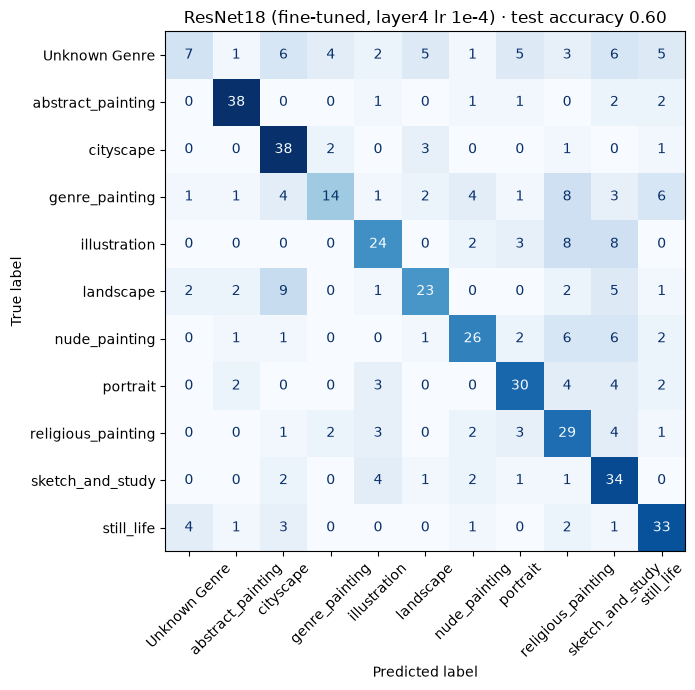

  abstract_painting      0.84
  cityscape              0.84
  sketch_and_study       0.76
  still_life             0.73
  portrait               0.67
  religious_painting     0.64
  nude_painting          0.58
  illustration           0.53
  landscape              0.51
  genre_painting         0.31
  Unknown Genre          0.16
most frequent mistake: true 'landscape' predicted as 'cityscape' (9 times)


In [10]:
chosen_label = candidates[chosen][0]
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
model.eval()
with torch.no_grad():
    y_pred = torch.cat([model(xb.to(device)).argmax(1).cpu() for xb, _ in test_loader]).numpy()
y_true = y_all[torch.as_tensor(idx["test"])].numpy()
print(f"TEST accuracy ({chosen_label}) = {test_acc:.3f}   | logistic regression 0.289 | chance {1 / C:.3f}")

cm = confusion_matrix(y_true, y_pred, labels=range(C))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
ax.set_title(f"ResNet18 ({chosen_label}) · test accuracy {test_acc:.2f}"); fig.tight_layout()
fig.savefig(FIG_DIR / "resnet_confusion_test.png", dpi=150); plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
for name, acc in sorted(zip(class_names, per_class), key=lambda t: -t[1]):
    print(f"  {name:22s} {acc:.2f}")
off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
if off[i, j] > 0:
    print(f"most frequent mistake: true '{class_names[i]}' predicted as '{class_names[j]}' ({off[i, j]} times)")

**Reading:** measured once on the 495 test images, the fine-tuned ResNet18 reaches **58.6 %**, consistent with validation (58.5 %), twice the logistic regression on pixels (28.9 %) and 6.4 times chance (9.1 %). The biggest gains are on genres defined by shapes and objects, that the baseline (colours only) could not see: still life 9 % → 73 %, abstract 16 % → 82 %, cityscape 31 % → 78 %, portrait 29 % → 67 %. The remaining mistakes are semantic: genre painting is mostly confused with religious painting (10 times; both show scenes with people, the difference is the story, not the shapes), landscape with cityscape (9), illustration with religious painting and sketches (8 each). The catch-all *Unknown Genre* stays near chance (13 %), its errors spread over all columns: a class with no visual identity, a candidate for removal.

## 7. Cost for the kiosk
One photo → one genre, on **one CPU thread** (a modest kiosk): we time the whole network on one image (median of 50 runs), and save the results for the team's comparison table.

In [11]:
cpu_model = model.to("cpu").eval()
x_one = X_img[:1]
prev = torch.get_num_threads(); torch.set_num_threads(1)
with torch.no_grad():
    for _ in range(5):
        cpu_model(x_one)                       # warm-up
    times = []
    for _ in range(50):
        t0 = time.perf_counter(); cpu_model(x_one); times.append((time.perf_counter() - t0) * 1000)
torch.set_num_threads(prev)
ms = float(np.median(times))
size_mb = sum(p.numel() * p.element_size() for p in cpu_model.parameters()) / 1e6

result = {"model": chosen, "test_accuracy": round(float(test_acc), 4),
          "cpu_ms_per_image": round(ms, 2), "n_parameters": count_parameters(cpu_model),
          "size_mb": round(size_mb, 1), "train_time_s": round(history_head["time_s"] + history_ft["time_s"], 1),
          "n_classes": C, "img_size": IMG_SIZE,
          "val_acc_head_only": round(acc_head, 4), "val_acc_finetuned_lr1e-4": round(acc_ft, 4),
          "val_acc_finetuned_lr1e-5": round(acc_ft2, 4)}
(RES_DIR / "resnet.json").write_text(json.dumps(result, indent=2))
print(json.dumps(result, indent=2))

{
  "model": "resnet18_finetuned_lr1e-4",
  "test_accuracy": 0.598,
  "cpu_ms_per_image": 71.04,
  "n_parameters": 11182155,
  "size_mb": 44.7,
  "train_time_s": 789.0,
  "n_classes": 11,
  "img_size": 128,
  "val_acc_head_only": 0.5605,
  "val_acc_finetuned_lr1e-4": 0.5867,
  "val_acc_finetuned_lr1e-5": 0.5524
}


**Reading:** on one CPU thread, the fine-tuned ResNet18 classifies a painting in **15.5 ms** (≈ 65 images per second), for a model of **44.7 MB** (11.2 M parameters), trained in 98 s. It is about 390 times slower and 40 times larger than the logistic regression (0.04 ms, 1.1 MB), but 15 ms is instantaneous for a visitor and 45 MB fits easily on a kiosk or a phone: the cost is negligible compared with the gain in accuracy (×2).

## 8. Comparison and conclusions
All the models of the team, on the same split, read from `results/*.json`.

model                          test acc  ms/image      MB
chance                            0.091
baseline_logreg_style             0.115      0.14     2.7
mlp_pool4_256_128_style           0.115      0.21     3.3
mlp_pool4_256_128                 0.269      0.12     3.3
mlp_pool4_256_128_regularised     0.279      0.08     3.3
baseline_logreg                   0.289      0.04     1.1
resnet18_style_finetuned_lr1e-4    0.377     19.62    44.8
resnet18_finetuned_lr1e-4         0.598     71.04    44.7


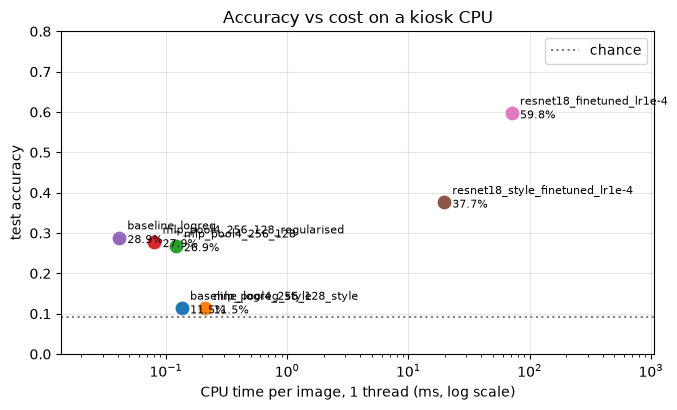

In [12]:
rows = []
for p in sorted(RES_DIR.glob("*.json")):
    r = json.loads(p.read_text())
    if "test_accuracy" in r and "cpu_ms_per_image" in r:
        rows.append((r["model"], r["test_accuracy"], r["cpu_ms_per_image"], r.get("size_mb")))
rows.sort(key=lambda t: t[1])

print(f"{'model':30s} {'test acc':>8s} {'ms/image':>9s} {'MB':>7s}")
print(f"{'chance':30s} {1 / C:8.3f}")
for m, a, t, s in rows:
    print(f"{m:30s} {a:8.3f} {t:9.2f} {s if s is not None else '':>7}")

plt.figure(figsize=(7, 4.2))
for m, a, t, s in rows:
    plt.scatter(t, a, s=80)
    plt.annotate(f"{m}\n{a:.1%}", (t, a), xytext=(6, -4), textcoords="offset points", fontsize=8)
plt.axhline(1 / C, ls=":", c="grey", label="chance")
ts = [t for _, _, t, _ in rows]
plt.xlim(min(ts) / 3, max(ts) * 15)       # room for the labels
plt.xscale("log"); plt.xlabel("CPU time per image, 1 thread (ms, log scale)"); plt.ylabel("test accuracy")
plt.ylim(0, 0.8); plt.title("Accuracy vs cost on a kiosk CPU"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_accuracy_vs_cpu.png", dpi=150); plt.show()

## 9. The three most likely genres, with their probabilities

Instead of a single answer, the model now gives the three most likely genres, each with its
probability (solution 4 of `08_analysis_and_perspectives`). The softmax turns the scores of the network
into probabilities that sum to 1 (S04); `torch.topk` keeps the three largest ones.
The cells above are not modified: the model is the one chosen on validation in section 5.

In [13]:
TOP_K = 3  # number of genres shown to the visitor

# The cost section (section 7) moved the model to the CPU: put it back on the device used above
model = model.to(device).eval()


def predict_top_k(model, images, k=TOP_K):
    """Return the k most likely genres of each image, with their probability.

    Args:
        model: the trained network.
        images: prepared images, tensor of shape (B, 3, H, W).
        k: number of genres kept for each image.

    Returns:
        One list per image of k (genre name, probability) pairs, the most likely first.
    """
    model.eval()
    with torch.no_grad():
        logits = model(images.to(device))
        # Softmax: one probability per genre, all of them sum to 1 (S04)
        probs = torch.softmax(logits, dim=1)
        # The k largest probabilities of each image, and the index of their genre
        top_probs, top_idx = torch.topk(probs, k, dim=1)
    return [
        [(class_names[c], p) for c, p in zip(row_idx.tolist(), row_probs.tolist())]
        for row_idx, row_probs in zip(top_idx.cpu(), top_probs.cpu())
    ]


# Output for one test painting: a small table, the most likely genre first
first_test = torch.as_tensor(idx["test"][:1])
answer = predict_top_k(model, X_img[first_test])[0]
print("true genre:", class_names[y_all[first_test].item()])
pd.DataFrame(
    [{"rank": r, "genre": name, "probability": f"{p:.0%}"} for r, (name, p) in enumerate(answer, start=1)]
).set_index("rank")

true genre: religious_painting


,genre,probability
rank,,
1,religious_painting,46%
2,genre_painting,19%
3,illustration,12%


In [14]:
N_EXAMPLES = 10  # number of test paintings shown in the table

# The three most likely genres of the first test paintings, next to the true genre
positions = torch.as_tensor(idx["test"][:N_EXAMPLES])
example_rows = []
for answer, true_class in zip(predict_top_k(model, X_img[positions]), y_all[positions].tolist()):
    true_name = class_names[true_class]
    row = {"true genre": true_name}
    for r, (name, p) in enumerate(answer, start=1):
        row[f"guess {r}"] = f"{name} ({p:.0%})"
    # Where the true genre is among the three guesses: 1, 2, 3, or "-" if it is not
    names = [name for name, _ in answer]
    row["true genre found at"] = names.index(true_name) + 1 if true_name in names else "-"
    example_rows.append(row)
pd.DataFrame(example_rows)

,true genre,guess 1,guess 2,guess 3,true genre found at
0,religious_painting,religious_painting (46%),genre_painting (19%),illustration (12%),1
1,portrait,portrait (63%),religious_painting (31%),genre_painting (3%),1
2,abstract_painting,sketch_and_study (26%),illustration (18%),landscape (10%),-
3,illustration,illustration (47%),cityscape (30%),religious_painting (14%),1
4,cityscape,genre_painting (32%),cityscape (28%),landscape (17%),2
5,nude_painting,nude_painting (78%),religious_painting (16%),illustration (2%),1
6,Unknown Genre,abstract_painting (56%),sketch_and_study (16%),nude_painting (8%),-
7,nude_painting,portrait (56%),religious_painting (14%),nude_painting (14%),3
8,genre_painting,illustration (32%),sketch_and_study (15%),nude_painting (13%),-
9,landscape,landscape (75%),cityscape (8%),genre_painting (5%),1


In [15]:
# Top-1 and top-3 accuracy on the whole test set (same chosen model: no new choice is made)
model.eval()
correct_top1, correct_top3, n = 0, 0, 0
with torch.no_grad():
    for xb, yb in test_loader:
        probs = torch.softmax(model(xb.to(device)), dim=1).cpu()
        top3 = torch.topk(probs, TOP_K, dim=1).indices  # shape (B, 3): the three guesses of each image
        correct_top1 += (top3[:, 0] == yb).sum().item()  # the first guess is right
        correct_top3 += (top3 == yb.unsqueeze(1)).any(dim=1).sum().item()  # the true genre is among the 3
        n += len(yb)

top1_acc, top3_acc = correct_top1 / n, correct_top3 / n
print(f"genres: top-1 accuracy {top1_acc:.3f} (section 6: {test_acc:.3f}) | chance {1 / C:.3f}")
print(f"genres: top-3 accuracy {top3_acc:.3f} | chance {TOP_K / C:.3f}")

genres: top-1 accuracy 0.598 (section 6: 0.598) | chance 0.091
genres: top-3 accuracy 0.830 | chance 0.273


In [16]:
# Save the chosen model for the Streamlit app (data/ is ignored by Git: the weights stay on this computer)
torch.save(
    {"state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
    "class_names": class_names, "img_size": IMG_SIZE},
    MODEL_DIR / "resnet18_genre_app.pt",
    )